In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

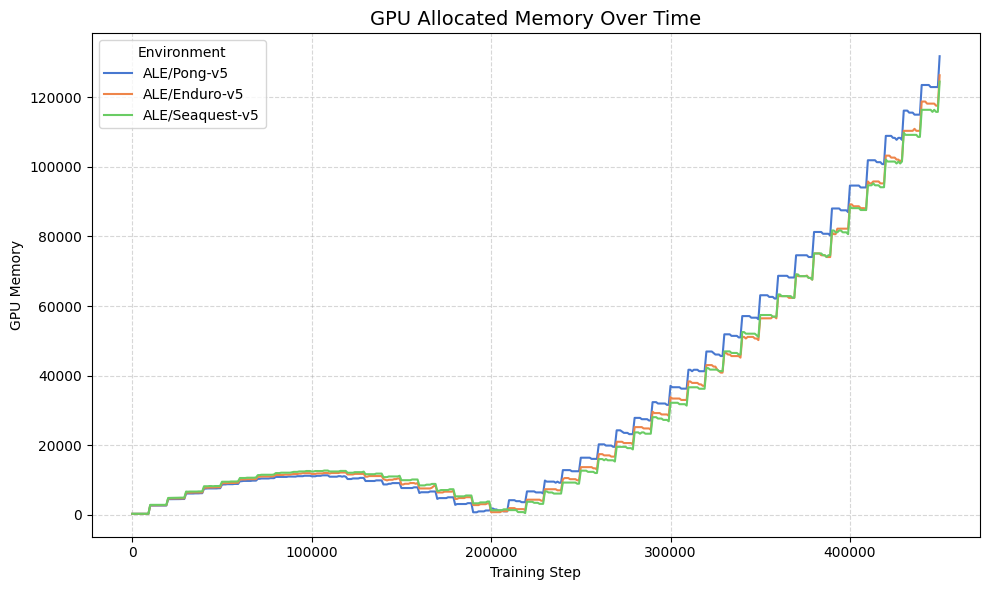

In [ ]:
df = pd.read_csv("/home/ran/datasets/gpu-mem-genius/all_data_combined.csv")

In [ ]:
#figure 5
df['percent_diff'] = np.abs(df['gpu_usage_percent'] - df['cpu_memory_percent'])
df['gpu_ratio'] = df['gpu_allocated_mb'] * df['percent_diff']

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=df,
    x="step",
    y="gpu_ratio",
    hue="game_name",
    palette="muted"
)

plt.title("GPU Allocated Memory Over Time", fontsize=14)
plt.xlabel("Training Step")
plt.ylabel("GPU Memory")
plt.legend(title="Environment")
plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

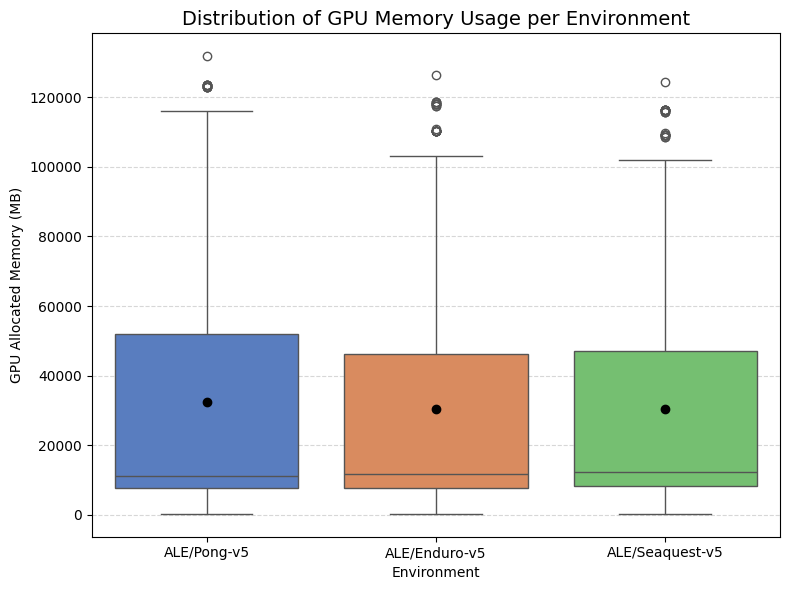

In [ ]:
# Figure 6
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=df,
    x="game_name",
    y="gpu_ratio",
    palette="muted",
    hue='game_name',
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "black", "markeredgecolor": "black"}
)

plt.title("Distribution of GPU Memory Usage per Environment", fontsize=14)
plt.xlabel("Environment")
plt.ylabel("GPU Allocated Memory (MB)")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

/tmp/ipykernel_24009/4191800155.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Environment")


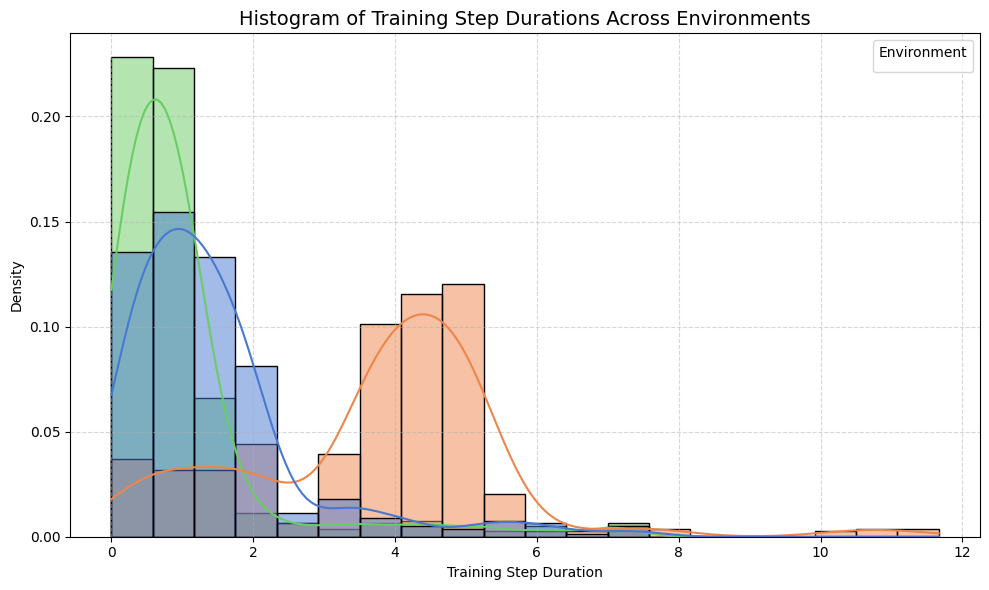

In [29]:
# figure 7
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x="duration",
    hue="game_name",
    multiple="layer",
    bins=20,
    palette="muted",
    kde=True,
    stat="density"
)

plt.title("Histogram of Training Step Durations Across Environments", fontsize=14)
plt.xlabel("Training Step Duration")
plt.ylabel("Density")
plt.legend(title="Environment")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Model Results charts

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def load_and_label(file, model_type, target):
    df = pd.read_csv(file)
    df["model_type"] = model_type
    df["target"] = target

    if target == "CPU":
        df.rename(columns={
            "actual_cpu_memory": "actual",
            "predicted_cpu_memory": "predicted"
        }, inplace=True)
    elif target == "GPU":
        df.rename(columns={
            "actual_gpu_memory": "actual",
            "predicted_gpu_memory": "predicted"
        }, inplace=True)
    # Compute absolute error
    df["abs_error"] = (df["actual"] - df["predicted"]).abs()
    return df

In [23]:
root_predictions = '/home/ran/models/gpu-mem-genius/results/predictions'

df_static_cpu = load_and_label(f"{root_predictions}/apriori_cpu.csv", "Static", "CPU")
df_static_gpu = load_and_label(f"{root_predictions}/apriori_gpu.csv", "Static", "GPU")
df_dynamic_cpu = load_and_label(f"{root_predictions}/dynamic_cpu.csv", "Dynamic", "CPU")
df_dynamic_gpu = load_and_label(f"{root_predictions}/dynamic_gpu.csv", "Dynamic", "GPU")

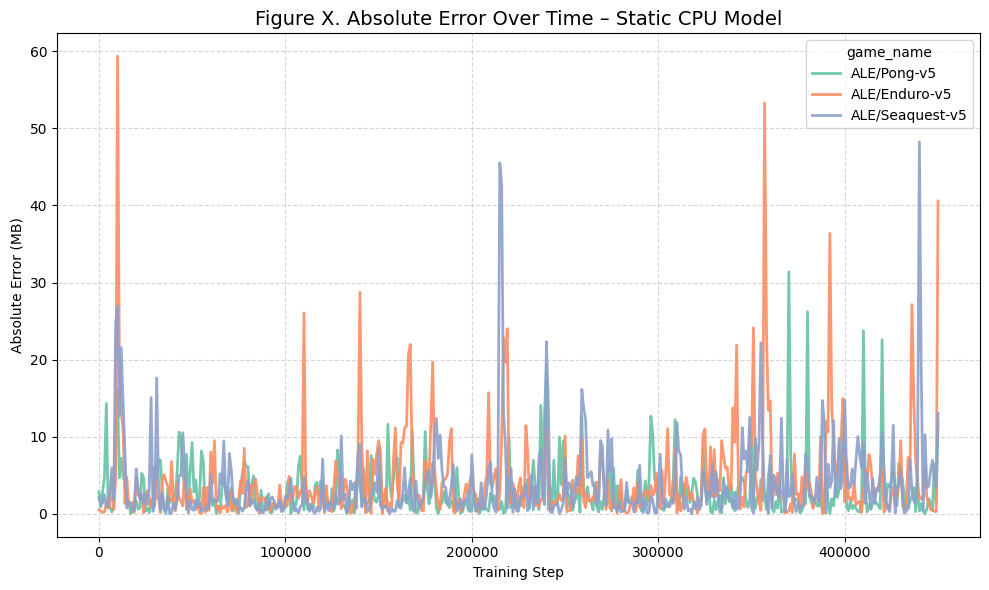

In [ ]:
# Plot absolute error over time
plt.fig1ure(figsize=(10, 6))
sns.lineplot(
    data=df_static_cpu,
    x="step",
    y="abs_error",
    hue="game_name",
    linewidth=2,
    alpha=0.9,
    palette="Set2"
)

plt.title("Figure X. Absolute Error Over Time – Static CPU Model", fontsize=14)
plt.xlabel("Training Step")
plt.ylabel("Absolute Error (MB)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

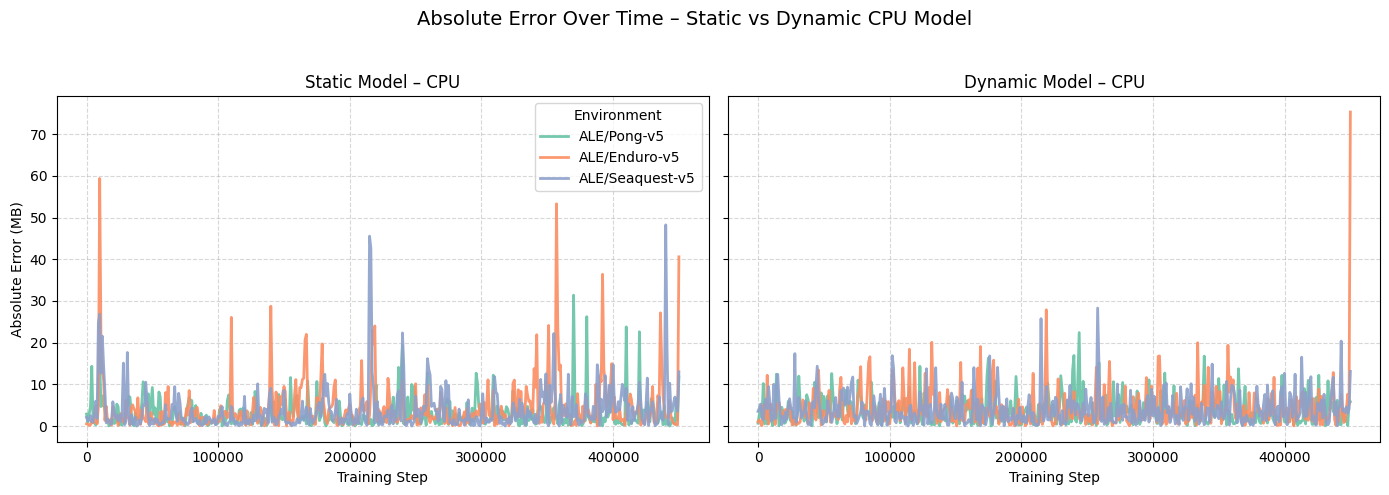

In [27]:
# Plot: 1 row, 2 subplots
df_static_cpu["model"] = "Static"
df_dynamic_cpu["model"] = "Dynamic"
df_cpu = pd.concat([df_static_cpu, df_dynamic_cpu])
# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, model in zip(axes, ["Static", "Dynamic"]):
    df_model = df_cpu[df_cpu["model"] == model]
    sns.lineplot(
        data=df_model,
        x="step",
        y="abs_error",
        hue="game_name",
        linewidth=2,
        alpha=0.9,
        palette="Set2",
        ax=ax
    )
    ax.set_title(f"{model} Model – CPU", fontsize=12)
    ax.set_xlabel("Training Step")
    ax.grid(True, linestyle="--", alpha=0.5)

axes[0].set_ylabel("Absolute Error (MB)")
axes[0].legend(title="Environment")
axes[1].legend().remove()

plt.suptitle("Absolute Error Over Time – Static vs Dynamic CPU Model", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

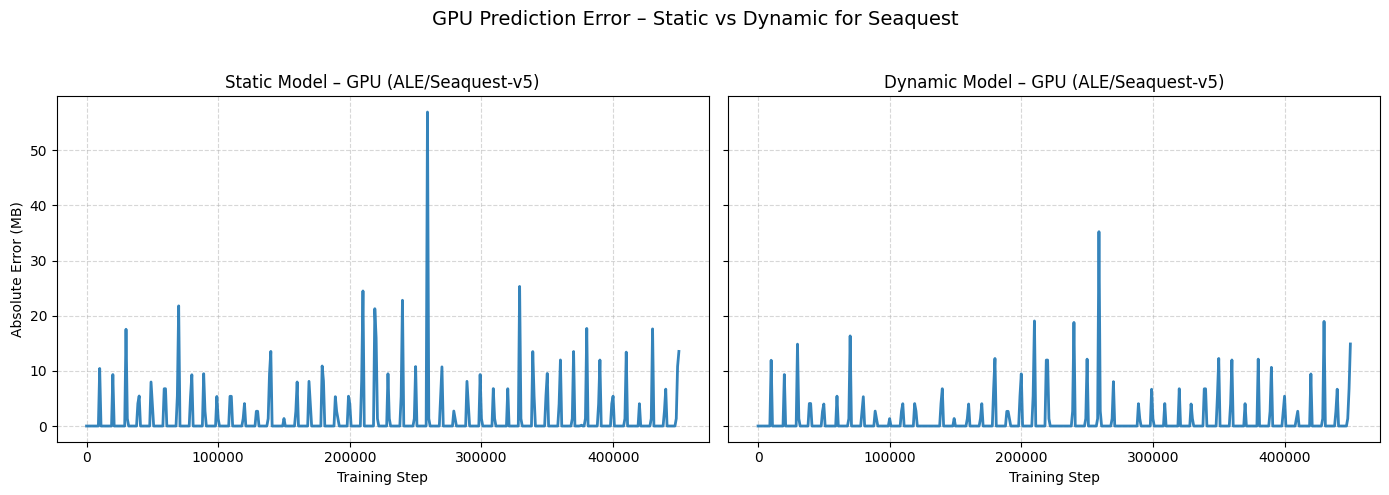

In [28]:
# Focus on one game
target_game = "ALE/Seaquest-v5"
df_static_gpu = df_static_gpu[df_static_gpu["game_name"] == target_game].copy()
df_dynamic_gpu = df_dynamic_gpu[df_dynamic_gpu["game_name"] == target_game].copy()

df_static_gpu["model"] = "Static"
df_dynamic_gpu["model"] = "Dynamic"

# Combine
df_gpu = pd.concat([df_static_gpu, df_dynamic_gpu])

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, model in zip(axes, ["Static", "Dynamic"]):
    df_model = df_gpu[df_gpu["model"] == model]
    sns.lineplot(
        data=df_model,
        x="step",
        y="abs_error",
        linewidth=2,
        alpha=0.9,
        color="#1f77b4",
        ax=ax
    )
    ax.set_title(f"{model} Model – GPU ({target_game})", fontsize=12)
    ax.set_xlabel("Training Step")
    ax.grid(True, linestyle="--", alpha=0.5)

axes[0].set_ylabel("Absolute Error (MB)")
plt.suptitle("GPU Prediction Error – Static vs Dynamic for Seaquest", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# models loss and training results

In [ ]:
def calculate_trimmed_nrmse(df, rmse_val, target_col, trim_k=4):
    actual_sorted = df[target_col].sort_values().reset_index(drop=True)
    trimmed = actual_sorted[trim_k: -trim_k]  # drop k smallest and k largest
    denom = (trimmed.max() - trimmed.min()) / 10
    return (rmse_val / denom)

In [73]:
# nrmse configurations
dynamic_r = 6
static_r = 7
nrmse_results = {}

In [74]:
for t in ["cpu", "gpu"]:
    for s in ["apriori", "dynamic"]:
        predictions_df = pd.read_csv(f"/home/ran/models/gpu-mem-genius/results/predictions/{s}_{t}.csv")
        summary_df = pd.read_csv(f"/home/ran/models/gpu-mem-genius/results/{s}_{t}_summary.csv")
        rmse_val = summary_df["RMSE_mean"].iloc[0]
        temp_val = dynamic_r if s == "dynamic" else static_r
        nrmse_val = calculate_trimmed_nrmse(predictions_df, rmse_val, f"actual_{t}_memory", trim_k=temp_val) * temp_val
        print(f"NRMSE {s}_{t}: {nrmse_val:.4f}")
        nrmse_results[f"{s}_{t}"] = nrmse_val

NRMSE apriori_cpu: 0.1981
NRMSE dynamic_cpu: 0.1673
NRMSE apriori_gpu: 0.1141
NRMSE dynamic_gpu: 0.0685


NRMSE (CPU Static): 0.1394


np.float64(0.21466804430896094)